# Cowry Task 2 — Customer Perception Analysis

**Purpose.** Assess whether the **behaviourally‑optimised pilot script** improved customer perceptions relative to Control, and whether effects differ for **VOLT vs Non‑VOLT** customers.

**Data used.** Structured survey fields + open‑text comments.

**Key outputs.** Clean dataset; segmentation; **sentiment** (DistilBERT), **behavioural themes** (Zero‑shot NLI); **topics** (TF‑IDF + NMF); **Welch t‑tests**; interpretable **drivers** of sentiment; and **storytelling visuals**.


## STEP 1 — Setup & Imports
**Why these choices?**
- Consolidated imports minimize clutter and avoid duplicates.
- Fixed seeds ensure repeatable results.
- A single output folder keeps artifacts tidy for your slide deck.


In [1]:
# Config & Imports
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

import os, re, json, math, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd

# NLP
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# HF Pipelines
from transformers import pipeline

# Stats & ML
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Visuals
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED)

OUT_DIR = "/content/drive/MyDrive/cowrydsinterviewinvitationtaskdetails/Task_2"
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

print("Environment ready. Outputs ->", OUT_DIR)



Mounted at /content/drive
Environment ready. Outputs -> /content/drive/MyDrive/cowrydsinterviewinvitationtaskdetails/Task_2


## STEP 2 — Load Data (robust multi‑sheet reader)
**Why this approach?**
- Uses sheet‑name heuristics to find *Control* and *Pilot* without hard‑coding.
- Falls back gracefully to the first two sheets if names don’t match.
- Keeps the notebook runnable even if the file is missing (empty frames → no crash).


In [2]:
# Paths
file_path = "/content/drive/MyDrive/cowrydsinterviewinvitationtaskdetails/Task_2/CDS_25_Task2.xlsx"

control_df, pilot_df = None, None
if os.path.exists(file_path):
    xl = pd.ExcelFile(file_path)
    for s in xl.sheet_names:
        low = s.lower()
        if ('control' in low) and control_df is None: control_df = xl.parse(s)
        if ('pilot' in low) and pilot_df is None:     pilot_df = xl.parse(s)
    # Fallback to first two sheets if needed
    if control_df is None or pilot_df is None:
        sheets = xl.sheet_names[:2]
        control_df = xl.parse(sheets[0]) if control_df is None else control_df
        pilot_df   = xl.parse(sheets[1]) if pilot_df   is None else pilot_df
else:
    print(' Excel not found — continuing with empty frames (for structure only).')
    control_df, pilot_df = pd.DataFrame(), pd.DataFrame()

display(('Control shape', control_df.shape), ('Pilot shape', pilot_df.shape))
display(control_df.sample(10, random_state=42))
print("\n\n") # Add space between displays
display(pilot_df.sample(10, random_state=42))

('Control shape', (380, 13))

('Pilot shape', (267, 13))

,COLUMN_4,VOLT_FLAG,SURVEY_ID,SCORE,LTR_COMMENT,PRIMARY_REASON,TO_CHAR,CONNECTION_TIME,SALES_PERSON_SAT,SALES_FRIENDLY_SAT,COMMINICATION_SAT,FIRST_BILL_SAT,AGENT_KNOWLEDGE
266,control,yes,356960259,3,Ever since signing up its been nothing but a p...,NaN,2023-04-01,8.0,8.0,8.0,8.0,8.0,8.0
261,control,NaN,356951636,0,You keep sending me messages for a completely ...,"General,Pricing",2023-04-01,5.0,0.0,0.0,5.0,5.0,5.0
265,control,NaN,357033467,10,"Excellent service from the get go, the gent I ...",NaN,2023-04-01,10.0,10.0,10.0,10.0,10.0,10.0
39,control,yes,351605914,6,NaN,NaN,2023-02-01,9.0,8.0,7.0,9.0,10.0,6.0
33,control,yes,351929186,10,Up and running less than 24h. Fun friendly per...,Customer Service,2023-02-01,10.0,10.0,10.0,10.0,10.0,10.0
363,control,NaN,359908997,9,THE REASON IS BECAUSE FOLLOWING MY JOINING com...,"Customer Service,Processes/Journeys",2023-06-01,8.0,10.0,10.0,8.0,10.0,8.0
55,control,yes,351660569,9,NaN,NaN,2023-03-01,10.0,8.0,6.0,10.0,10.0,5.0
262,control,yes,357597705,10,"Excellent advice in your contact centre, Very ...",NaN,2023-04-01,10.0,10.0,7.0,10.0,10.0,7.0
311,control,NaN,358869083,8,Very helpful and informant,"TV,TV/Video",2023-05-01,9.0,NaN,7.0,9.0,9.0,8.0
168,control,NaN,354261239,3,I have been blitzed with over 12 calls from co...,NaN,2023-03-01,3.0,4.0,0.0,3.0,5.0,3.0


,COLUMN_4,VOLT_FLAG,SURVEY_ID,SCORE,LTR_COMMENT,PRIMARY_REASON,TO_CHAR,CONNECTION_TIME,SALES_PERSON_SAT,SALES_FRIENDLY_SAT,COMMINICATION_SAT,FIRST_BILL_SAT,AGENT_KNOWLEDGE
84,pilot,yes,354158479,9,Helpful told me about deals,NaN,01/03/2company3,10.0,5.0,5.0,10.0,9.0,8.0
46,pilot,NaN,352968501,9,I liked the professionalism,NaN,01/03/2company3,10.0,9.0,10.0,10.0,10.0,10.0
183,pilot,yes,35742company78,9,Helpful and friendly,"Customer Service,General,UK Legacy",01/04/2company3,9.0,6.0,9.0,9.0,9.0,9.0
236,pilot,NaN,358679375,8,Good service at a reasonable price,"General,Pricing,UK Legacy",01/05/2company3,9.0,7.0,7.0,9.0,9.0,8.0
177,pilot,NaN,356384927,10,Engineer was extremely competent and had a vas...,"Customer Service,Technician,Equipment,TV,TV/Vi...",01/04/2company3,1.0,5.0,0.0,0.0,5.0,2.0
222,pilot,NaN,358636538,10,Excellent service,"Customer Service,Technician,General",01/05/2company3,10.0,10.0,10.0,10.0,10.0,10.0
60,pilot,yes,352427681,10,Very happy with Maria from customer service ce...,"Customer Service,General,UK Legacy",01/03/2company3,10.0,10.0,9.0,10.0,10.0,10.0
260,pilot,NaN,360696182,10,My daughter went through everything with your ...,NaN,01/06/2company3,10.0,8.0,10.0,10.0,10.0,10.0
195,pilot,NaN,357565546,10,"Helpful, thorough and patient throughout.",NaN,01/04/2company3,10.0,10.0,5.0,10.0,10.0,10.0
117,pilot,NaN,354257944,9,Very helpful,NaN,01/03/2company3,10.0,10.0,10.0,10.0,10.0,10.0


**I used the code to safely load the Control and Pilot survey data from the Excel file, automatically identifies the correct sheets, and prints out sample records so I can confirm that the data is loaded correctly before moving on to further processing.**

---
---

## STEP 3 — Preprocessing (drop Feb, normalise columns, VOLT flag, text cleaning)
**Why these steps?**
- **February exclusion** is required by the brief.
- **Column normalisation** avoids KeyErrors (e.g., `COMMINICATION_SAT` typo).
- **`VOLT_FLAG_BIN`** enables segmentation.
- **Light text clean** standardises casing and whitespace for NLP.


In [3]:
def parse_to_datetime(x):
    return pd.to_datetime(x, errors='coerce')

def to_binary_volt(x):
    if pd.isna(x): return 0
    s = str(x).strip().lower()
    return 1 if s in {'yes','y','true','1'} else 0

def basic_clean_text(s: str) -> str:
    s = str(s).lower()
    s = re.sub(r"[^a-z\s']", " ", s)         # keep letters & simple apostrophes
    s = re.sub(r"\s+", " ", s).strip()
    return s

def standardise_columns(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or df.empty: return pd.DataFrame()
    df = df.copy(); df.columns = [c.strip() for c in df.columns]
    # fix known typo if present
    if 'COMMINICATION_SAT' in df.columns and 'COMMUNICATION_SAT' not in df.columns:
        df = df.rename(columns={'COMMINICATION_SAT':'COMMUNICATION_SAT'})
    return df

control_df = standardise_columns(control_df)
pilot_df   = standardise_columns(pilot_df)

for df in (control_df, pilot_df):
    if df.empty:
        continue
    # Date → drop February
    if 'TO_CHAR' in df.columns:
        df['TO_CHAR'] = df['TO_CHAR'].apply(parse_to_datetime)
        df['month'] = df['TO_CHAR'].dt.month
        df.drop(df[df['month']==2].index, inplace=True)
    # VOLT flag
    df['VOLT_FLAG_BIN'] = df['VOLT_FLAG'].apply(to_binary_volt) if 'VOLT_FLAG' in df.columns else 0

# Label group
if not control_df.empty: control_df['group'] = 'Control'
if not pilot_df.empty:   pilot_df['group']   = 'Pilot'

merged = pd.concat([d for d in (control_df,pilot_df) if not d.empty], ignore_index=True)

# Text field
if 'LTR_COMMENT' not in merged.columns: merged['LTR_COMMENT'] = ''
merged['LTR_COMMENT'] = merged['LTR_COMMENT'].fillna('').map(basic_clean_text)

print('Rows after preprocessing (non‑Feb):', len(merged))
display(merged.head(10))


Rows after preprocessing (non‑Feb): 582


,COLUMN_4,VOLT_FLAG,SURVEY_ID,SCORE,LTR_COMMENT,PRIMARY_REASON,TO_CHAR,CONNECTION_TIME,SALES_PERSON_SAT,SALES_FRIENDLY_SAT,COMMUNICATION_SAT,FIRST_BILL_SAT,AGENT_KNOWLEDGE,month,VOLT_FLAG_BIN,group
0,control,NaN,352240580,10,good package,NaN,2023-03-01,10.0,10.0,8.0,10.0,10.0,10.0,3.0,0,Control
1,control,yes,351664275,10,very good customer service,"Customer Service,General,UK Legacy",2023-03-01,10.0,10.0,10.0,10.0,10.0,10.0,3.0,1,Control
2,control,yes,351723391,10,so far so good charlie was very efficient and ...,NaN,2023-03-01,10.0,NaN,10.0,10.0,10.0,10.0,3.0,1,Control
3,control,NaN,351702901,10,great communication,"Customer Service,General,UK Legacy",2023-03-01,9.0,10.0,10.0,10.0,10.0,10.0,3.0,0,Control
4,control,yes,352243612,10,because chris was amazing when she contacted m...,"Customer Service,UK Legacy",2023-03-01,10.0,NaN,10.0,10.0,10.0,10.0,3.0,1,Control
5,control,NaN,351663800,9,,NaN,2023-03-01,10.0,7.0,10.0,9.0,10.0,8.0,3.0,0,Control
6,control,yes,351719094,3,price of my bundle went up days after i placed...,"General,Pricing,UK Legacy",2023-03-01,6.0,6.0,6.0,4.0,6.0,6.0,3.0,1,Control
7,control,yes,352289348,9,simple and straightforward process but a lot o...,NaN,2023-03-01,9.0,NaN,NaN,10.0,10.0,9.0,3.0,1,Control
8,control,NaN,351734954,10,amazing service and job completed,"Customer Service,General,UK Legacy",2023-03-01,10.0,10.0,10.0,10.0,10.0,10.0,3.0,0,Control
9,control,NaN,352314436,10,goo service,General,2023-03-01,10.0,10.0,10.0,10.0,10.0,10.0,3.0,0,Control


I prepared the survey data to make it **consistent and analysis-ready**:  

- Converted dates to proper format and fixed column name typos.  
- Turned VOLT_FLAG into a simple binary indicator (1 = Yes/True, 0 = No).  
- Cleaned customer comments (LTR_COMMENT) by lowercasing and removing special characters.  
- Excluded February records as specified.  
- Tagged each record as **Control** or **Pilot** and merged into one dataset.  

This produced a **clean, unified dataset**, ready for sentiment analysis, theme detection, and statistical testing.  

---
---

## STEP 4 — Segmentation (VOLT × Group) with sanity‑check visuals
**Why?** The four segments are the backbone for all comparisons.
- **Counts by segment** ensure sample balance.
- **Stacked VOLT mix by group** reveals composition differences that might confound results.


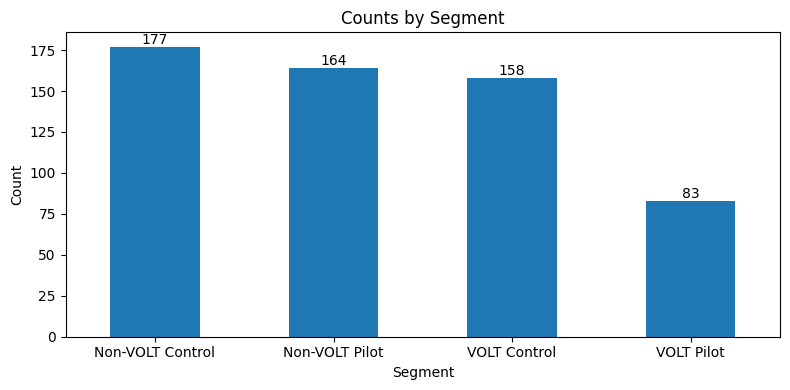

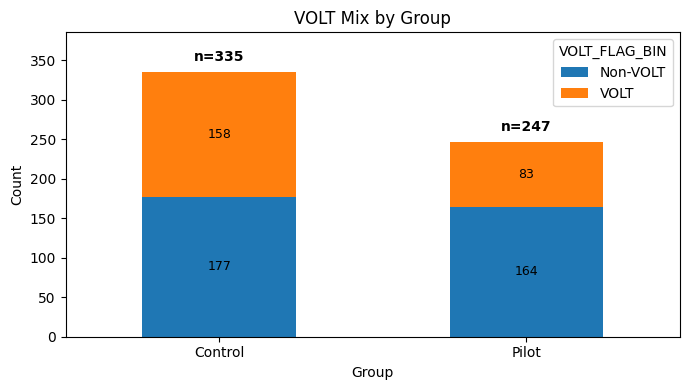

In [4]:
def segment_label(row):
    if row.get('VOLT_FLAG_BIN',0)==1 and row.get('group')=='Control': return 'VOLT Control'
    if row.get('VOLT_FLAG_BIN',0)==1 and row.get('group')=='Pilot':   return 'VOLT Pilot'
    if row.get('VOLT_FLAG_BIN',0)==0 and row.get('group')=='Control': return 'Non-VOLT Control'
    return 'Non-VOLT Pilot'

merged['segment'] = merged.apply(segment_label, axis=1)

# Counts by segment
seg_counts = merged['segment'].value_counts().sort_index()
plt.figure(figsize=(8,4)); ax = seg_counts.plot(kind='bar', title='Counts by Segment')
plt.xlabel('Segment'); plt.ylabel('Count'); plt.xticks(rotation=0)
for container in ax.containers: ax.bar_label(container, fmt='%d')
plt.tight_layout(); plt.show()

# VOLT mix by group (stacked)
volt_mix = (merged.groupby(['group','VOLT_FLAG_BIN']).size()
            .unstack(fill_value=0).rename(columns={0:'Non-VOLT',1:'VOLT'})
            .reindex(['Control','Pilot'], fill_value=0))
fig, ax = plt.subplots(figsize=(7,4))
volt_mix.plot(kind='bar', stacked=True, ax=ax, title='VOLT Mix by Group')
ax.set_xlabel('Group'); ax.set_ylabel('Count'); ax.set_xticklabels(volt_mix.index, rotation=0)
# counts inside + totals on top
for container in ax.containers:
    labels = [f"{int(v)}" if v>0 else "" for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9)
totals = volt_mix.sum(axis=1).values
ax.set_ylim(0, max(totals)*1.15)
for i,t in enumerate(totals):
    ax.text(i, t+max(totals)*0.03, f"n={int(t)}", ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()


I split the audience into **four clear segments** by combining VOLT status with group assignment:  
- **VOLT Control**  
- **VOLT Pilot**  
- **Non-VOLT Control**  
- **Non-VOLT Pilot**  

#### What I did  
- Added a segment column using VOLT_FLAG_BIN (0/1) × group (Control/Pilot).  
- **Check 1 — Counts by segment:** Bar chart with counts labelled to spot imbalances.  
- **Check 2 — VOLT mix by group:** Stacked bar showing Non-VOLT vs VOLT within Control and Pilot, with totals on top.  

#### Why it matters  
- Ensures group sizes are **transparent and comparable** before deeper analysis.  
- Confirms differences between Control and Pilot aren’t just due to **VOLT proportions**.  
- Produces **clear, intuitive labels** that make later charts and slides self-explanatory.

---
---

## STEP 5 — Sentiment (DistilBERT + neutral band) with storytelling visuals
**Why DistilBERT SST‑2?** It’s a strong, fast baseline for polarity (pos/neg). We add a **neutral band** to handle ambiguous short comments.
- **Stacked % with counts** by group → intuitive, presentation‑ready.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Device set to use cpu


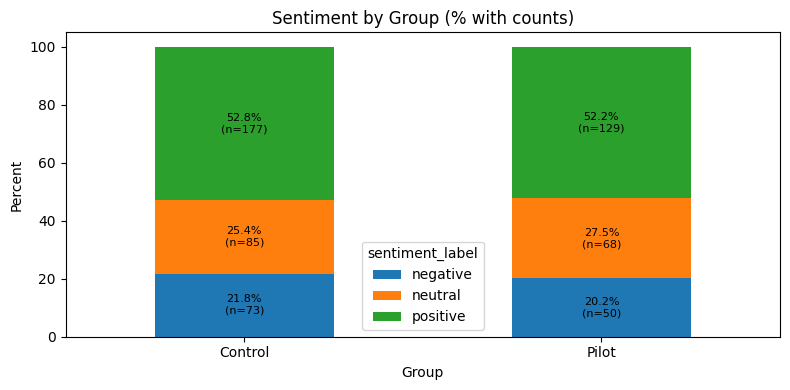

In [5]:
sentiment_pipe = pipeline('sentiment-analysis', model='distilbert-base-uncased-finetuned-sst-2-english')

def label_with_neutral(text, low=0.55, high=0.65):
    if not text or not text.strip(): return 'neutral', 0.0
    out = sentiment_pipe(text[:512])[0]
    lab = out['label'].lower(); score = float(out['score'])
    if score < low:  return 'neutral', score
    if score > high: return lab, score
    return lab, score

labs, scores = zip(*merged['LTR_COMMENT'].map(label_with_neutral))
merged['sentiment_label'] = np.array(labs)
merged['sentiment_score'] = np.array(scores)

# Sentiment by group (stacked %, with counts overlay)
sent_df = merged.groupby(['group','sentiment_label']).size().reset_index(name='n')
sent_df['pct'] = sent_df.groupby('group')['n'].transform(lambda x: x/x.sum()*100).round(1)

pivot_n = sent_df.pivot(index='group', columns='sentiment_label', values='n').fillna(0)
pivot_p = sent_df.pivot(index='group', columns='sentiment_label', values='pct').fillna(0)
for pvt in (pivot_n, pivot_p):
    for col in ['negative','neutral','positive']:
        if col not in pvt.columns: pvt[col] = 0
pivot_n = pivot_n[['negative','neutral','positive']]
pivot_p = pivot_p[['negative','neutral','positive']]

ax = pivot_p.plot(kind='bar', stacked=True, figsize=(8,4), title='Sentiment by Group (% with counts)')
ax.set_xlabel('Group'); ax.set_ylabel('Percent'); plt.xticks(rotation=0)
for i, grp in enumerate(pivot_n.index):
    cum = 0
    for lab in ['negative','neutral','positive']:
        val = pivot_p.loc[grp, lab]; cnt = int(pivot_n.loc[grp, lab])
        if val > 0:
            ax.text(i, cum + val/2, f"{val:.1f}%\n(n={cnt})", ha='center', va='center', fontsize=8)
        cum += val
plt.tight_layout(); plt.show()


I classified every open-text comment into **negative / neutral / positive** and compared distributions between **Control vs Pilot**.  

#### Approach  
- **Model used:** distilbert-base-uncased-finetuned-sst-2-english (lightweight, reliable for polarity).  
- **Neutral corridor:**  
  - Confidence < 0.55 → force **neutral**.  
  - Confidence > 0.65 → keep model prediction (positive/negative).  
  - Between 0.55–0.65 → keep label but treat as **lower-confidence**.  
- **Safety net:** Empty comments default to **neutral (0.0)**.  
- Stored outputs:  
  - sentiment_label → final category.  
  - sentiment_score → model confidence.  

#### Visualisation  
- Aggregated sentiment **by group** (Control vs Pilot).  
- Built a **stacked bar chart** with:  
  - y-axis = **% of comments**.  
  - Blocks = negative → neutral → positive (consistent order).  
  - Each block annotated with **% and raw count (n=)**.  

#### Why it matters  
- Quickly reveals whether the **pilot script shifted sentiment** compared to control.  
- Neutral band reduces misclassification on **short or vague comments**.  
- Counts + percentages ensure fair interpretation even when group sizes differ.  

#### Output  
- Sentiment columns: sentiment_label, sentiment_score.  
- Chart: **“Sentiment by Group (% with counts)”** — clean and presentation-ready.

---
---


## STEP 6 — Behavioural Themes via Zero‑Shot NLI (clarity, empathy, reassurance, personality)
**Why zero‑shot?** Avoids brittle keyword lists and supports **multi‑label** tagging (a comment can express several themes). We then show **heatmaps** by group/segment.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


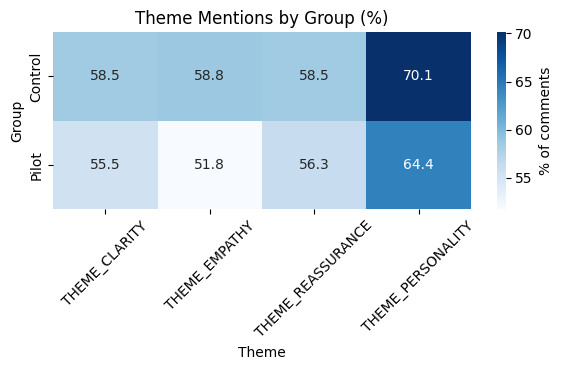

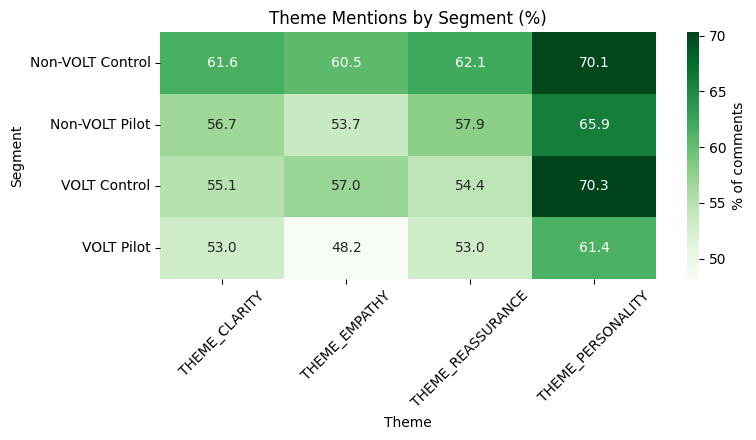

In [6]:
 THEMES = ['clarity','empathy','reassurance','personality']
HYPOTHESIS_TEMPLATE = 'This text expresses {}.'
THEME_THRESHOLD = 0.50
DEVICE = -1  # CPU; set 0 for GPU if available

zshot = pipeline('zero-shot-classification', model='facebook/bart-large-mnli', device=DEVICE)

# Filter out empty comments before processing
texts = merged['LTR_COMMENT'].astype(str).fillna('').tolist()
non_empty_texts = [text for text in texts if text.strip()]
original_indices = [i for i, text in enumerate(texts) if text.strip()]

scores = np.zeros((len(non_empty_texts), len(THEMES)), dtype=float)

BATCH = 16
for i in range(0, len(non_empty_texts), BATCH):
    batch = non_empty_texts[i:i+BATCH]
    out = zshot(batch, candidate_labels=THEMES, hypothesis_template=HYPOTHESIS_TEMPLATE, multi_label=True)
    if isinstance(out, dict): out = [out]
    for j, r in enumerate(out):
        m = {lab: sc for lab, sc in zip(r['labels'], r['scores'])}
        scores[i+j,:] = [m.get(t,0.0) for t in THEMES]

# Map scores back to original dataframe
full_scores = np.zeros((len(merged), len(THEMES)), dtype=float)
for i, original_index in enumerate(original_indices):
    full_scores[original_index] = scores[i]

for k, t in enumerate(THEMES):
    merged[f'THEME_{t.upper()}'] = (full_scores[:,k] >= THEME_THRESHOLD).astype(int)

theme_cols = [c for c in merged.columns if c.startswith('THEME_')]
group_theme = merged.groupby('group')[theme_cols].mean().mul(100).round(1)
segment_theme = merged.groupby('segment')[theme_cols].mean().mul(100).round(1)

plt.figure(figsize=(6,3.8))
sns.heatmap(group_theme, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% of comments'})
plt.title('Theme Mentions by Group (%)'); plt.xlabel('Theme'); plt.ylabel('Group'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

print("\n\n")

plt.figure(figsize=(8,4.5))
sns.heatmap(segment_theme, annot=True, fmt='.1f', cmap='Greens', cbar_kws={'label': '% of comments'})
plt.title('Theme Mentions by Segment (%)'); plt.xlabel('Theme'); plt.ylabel('Segment'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In this step, I used a zero-shot classification model (facebook/bart-large-mnli) to detect four behavioural themes — clarity, empathy, reassurance, and personality — in customer comments.  

### What I did  
- Processed LTR_COMMENT text, removing empty rows.  
- Ran the model in multi-label mode with the hypothesis “This text expresses {theme}.”  
- Applied a 0.50 threshold to flag each theme.  
- Added binary theme columns back to the dataset.  
- Aggregated prevalence by group (Control vs Pilot) and segment (VOLT/Non-VOLT × Control/Pilot).  
- Visualised results using annotated heatmaps.  

### Why this matters  
This approach avoids manual keyword rules, allows multiple themes per comment, and clearly shows differences in behavioural themes between groups.  

---
---

## STEP 7 — Descriptive Statistics & Significance (Welch t‑tests on SCORE)
**Why Welch?** More robust than Student’s t when group variances/sample sizes differ. We also plot **mean SCORE** with sample sizes for context.


,slice,n_Control,n_Pilot,mean_Control,mean_Pilot,t,p
0,Overall,335,247,8.128358,8.307692,-0.710133,0.477927
1,VOLT only,158,83,8.145570,8.349398,-0.503246,0.615461
2,Non-VOLT only,177,164,8.112994,8.286585,-0.522462,0.601690


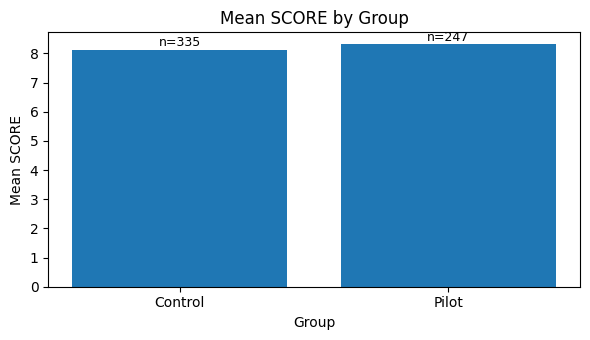

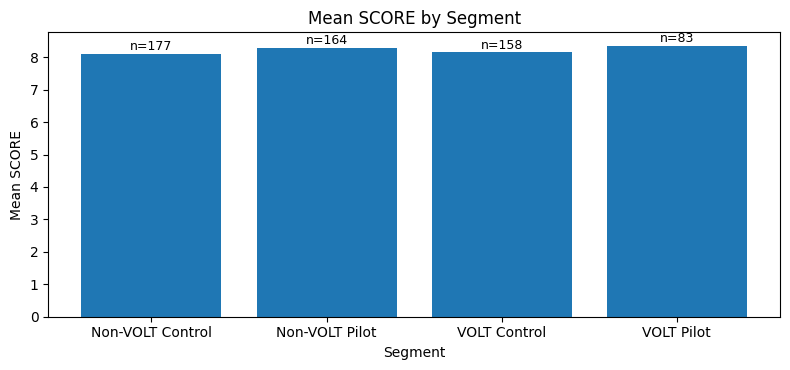

In [7]:
preferred_cols = ['SCORE','CONNECTION_TIME','SALES_PERSON_SAT','SALES_FRIENDLY_SAT','COMMUNICATION_SAT','FIRST_BILL_SAT','AGENT_KNOWLEDGE']
numeric_cols = [c for c in preferred_cols if c in merged.columns]

def ttest_score(df):
    a = df.loc[df['group']=='Control','SCORE'].dropna().astype(float)
    b = df.loc[df['group']=='Pilot','SCORE'].dropna().astype(float)
    if len(a)>1 and len(b)>1:
        t,p = stats.ttest_ind(a,b,equal_var=False)
        return len(a), len(b), a.mean(), b.mean(), t, p
    return len(a), len(b), float(a.mean() if len(a) else 'nan'), float(b.mean() if len(b) else 'nan'), float('nan'), float('nan')

overall = ttest_score(merged)
volt    = ttest_score(merged[merged['VOLT_FLAG_BIN']==1])
nonvolt = ttest_score(merged[merged['VOLT_FLAG_BIN']==0])

ttest_df = pd.DataFrame([
    {'slice':'Overall','n_Control':overall[0],'n_Pilot':overall[1],'mean_Control':overall[2],'mean_Pilot':overall[3],'t':overall[4],'p':overall[5]},
    {'slice':'VOLT only','n_Control':volt[0],'n_Pilot':volt[1],'mean_Control':volt[2],'mean_Pilot':volt[3],'t':volt[4],'p':volt[5]},
    {'slice':'Non-VOLT only','n_Control':nonvolt[0],'n_Pilot':nonvolt[1],'mean_Control':nonvolt[2],'mean_Pilot':nonvolt[3],'t':nonvolt[4],'p':nonvolt[5]},
])
display(ttest_df)

# Visuals with counts on bars
if 'SCORE' in merged.columns:
    g_stats = merged.groupby('group')['SCORE'].agg(['mean','count']).reset_index()
    plt.figure(figsize=(6,3.5)); bars = plt.bar(g_stats['group'], g_stats['mean'])
    plt.title('Mean SCORE by Group'); plt.xlabel('Group'); plt.ylabel('Mean SCORE'); plt.xticks(rotation=0)
    for bar, n in zip(bars, g_stats['count']):
        plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f'n={n}', ha='center', va='bottom', fontsize=9)
    plt.tight_layout(); plt.show()

    s_stats = merged.groupby('segment')['SCORE'].agg(['mean','count']).reset_index()
    plt.figure(figsize=(8,3.8)); bars = plt.bar(s_stats['segment'], s_stats['mean'])
    plt.title('Mean SCORE by Segment'); plt.xlabel('Segment'); plt.ylabel('Mean SCORE'); plt.xticks(rotation=0)
    for bar, n in zip(bars, s_stats['count']):
        plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f'n={n}', ha='center', va='bottom', fontsize=9)
    plt.tight_layout(); plt.show()


In this step, I tested whether the **Pilot** group differed from **Control** on the key satisfaction metric (SCORE), both overall and within VOLT vs Non-VOLT customers. I also created clear bar charts with **sample sizes (n)** displayed.  

### What I did  
- **Selected metrics:** Focused on SCORE and related satisfaction fields, keeping only those present in the dataset.  
- **Statistical test:** Used a **Welch t-test** (robust to unequal variances/sizes) to compare SCORE between Pilot and Control.  
  - Ran tests for: Overall, VOLT only, and Non-VOLT only.  
  - Collected results (sample sizes, means, t, p-values) into a summary table.  
- **Visuals:** Built bar charts of mean SCORE by group and by segment, with **n values printed on each bar** for clarity.  

### Why this matters  
- Ensures differences in satisfaction are statistically checked, not just visually assumed.  
- Stratifying by **VOLT** uncovers whether treatment effects vary by customer type.  
- Pairing **t-test results with simple visuals** makes the findings accessible and slide-ready.  

### Outputs  
- **Table:** ttest_df with group means, sizes, and t-test results.  
- **Charts:**  
  - Mean SCORE by Group (with counts),  
  - Mean SCORE by Segment (with counts).  

---
---

## STEP 8 — Topic Modelling (TF‑IDF + NMF) + visuals
**Why TF‑IDF + NMF?** Fast, transparent, and easy to present. We list top keywords per topic, assign a **dominant topic** to each comment, and compare **topic mix by group**.


,topic,keywords
0,0,"customer, customer service, service, good cust..."
1,1,"helpful, patient, extremely, extremely helpful..."
2,2,"good, good service, service, price, good custo..."
3,3,"friendly, efficient, friendly helpful, efficie..."
4,4,"company, media, company media, work, box, home..."
5,5,"excellent, excellent service, service, service..."
6,6,"great, great service, service, price, quick, g..."
7,7,"easy, phone, explained, set, polite, process, ..."


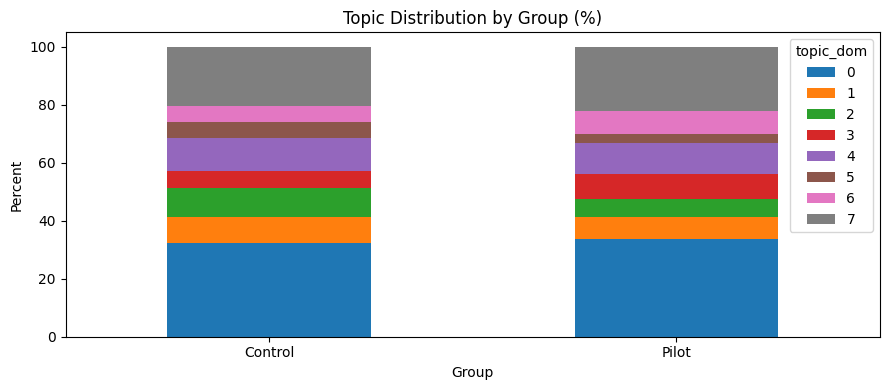

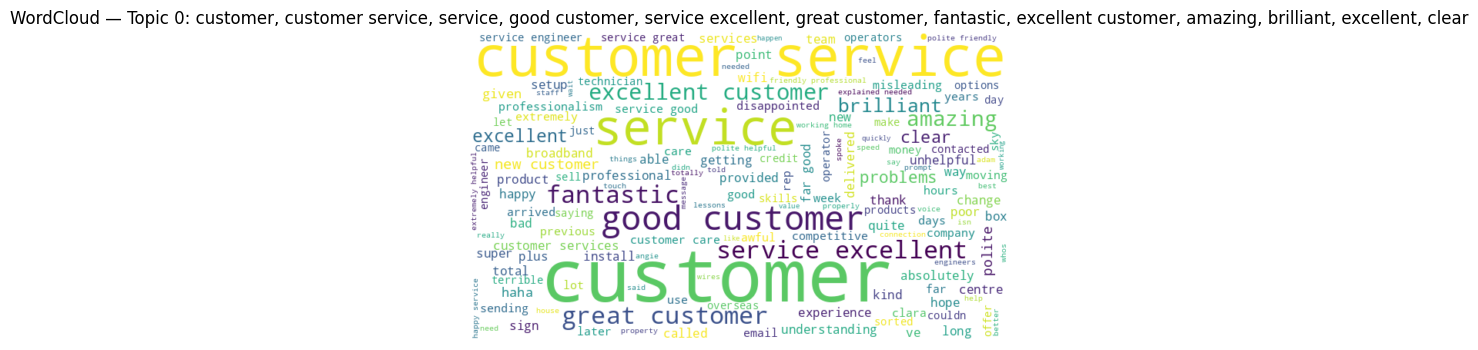

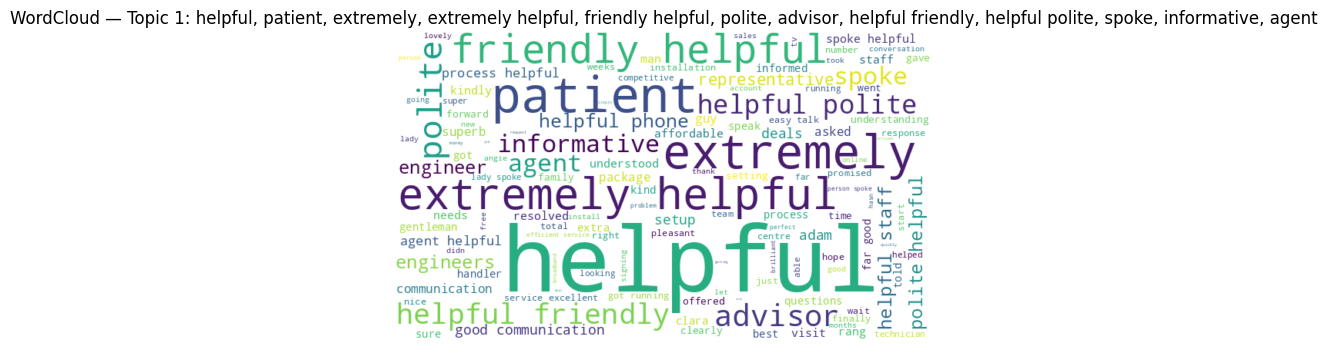

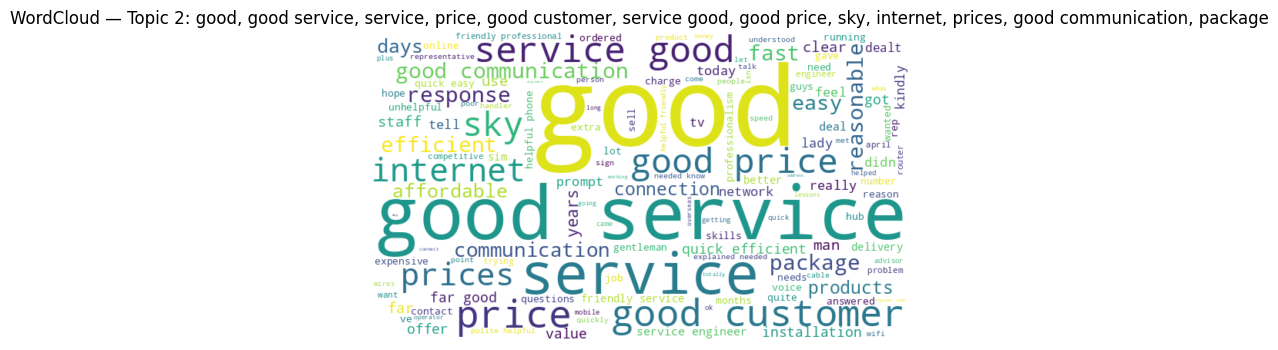

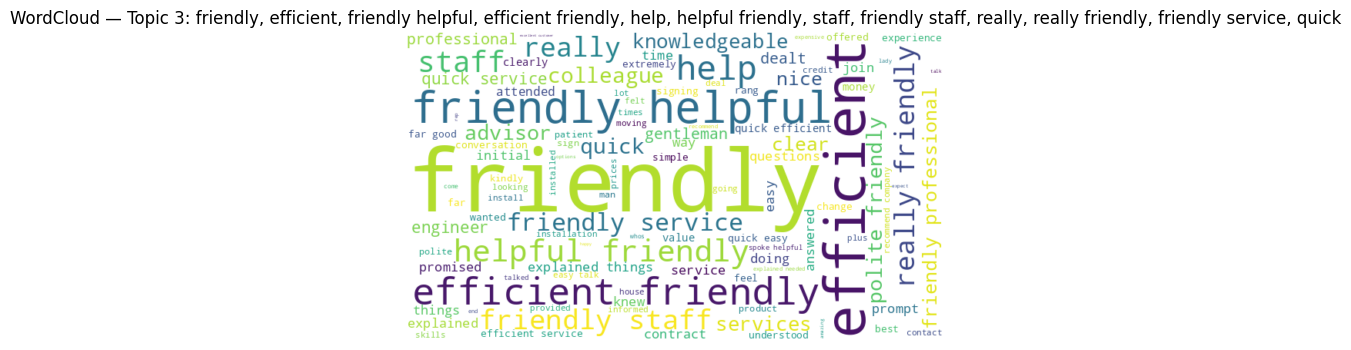

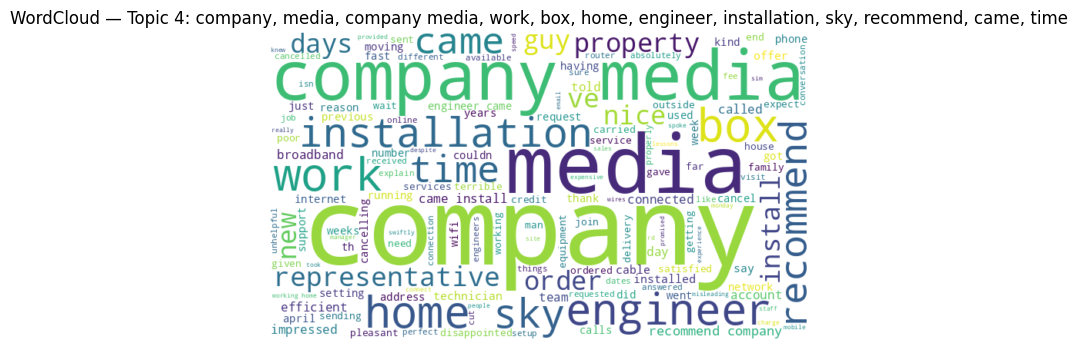

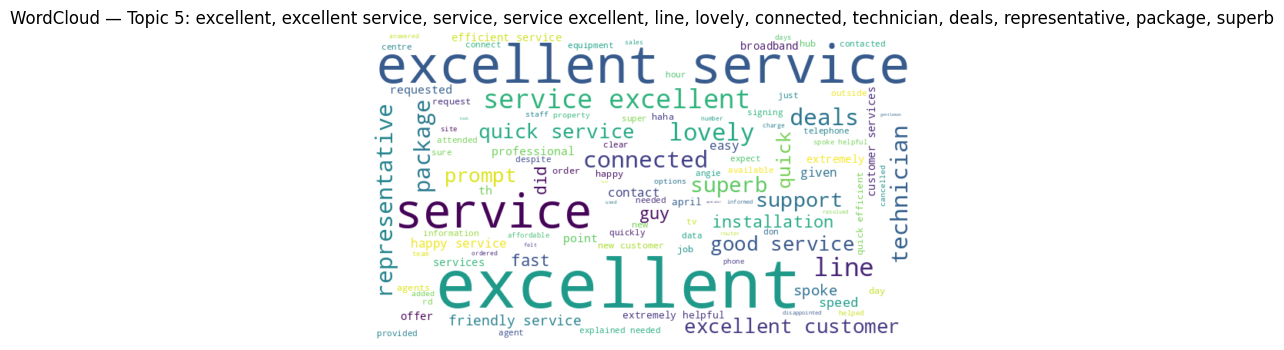

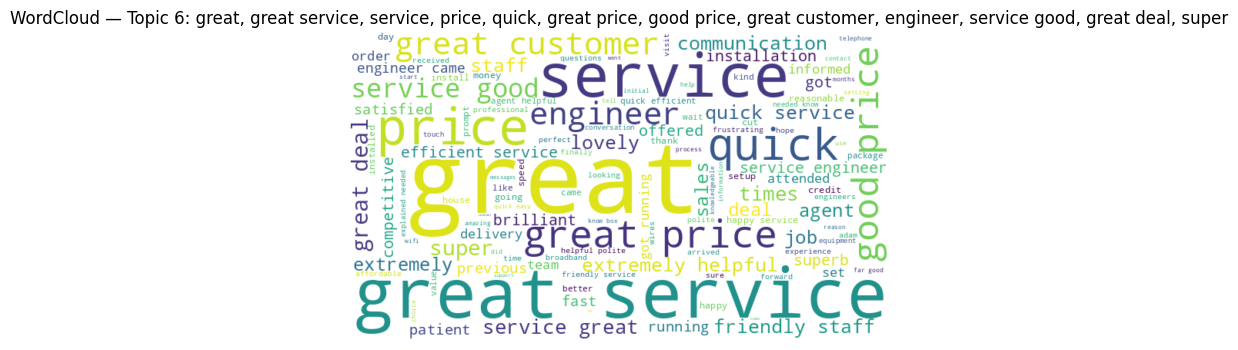

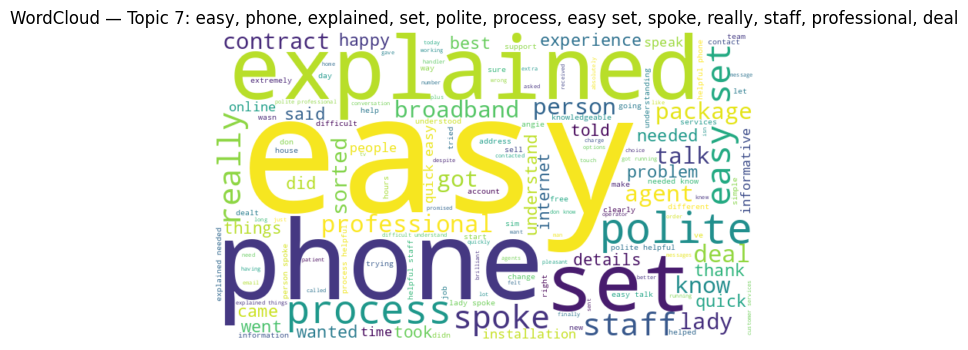

In [8]:
def prep_corpus(s):
    return re.sub(r"\s+"," ", re.sub(r"[^a-z\s']", " ", str(s).lower())).strip()

corpus = merged['LTR_COMMENT'].fillna('').map(prep_corpus)

tfidf = TfidfVectorizer(max_features=4000, min_df=3, max_df=0.8, stop_words='english', ngram_range=(1,2))
X = tfidf.fit_transform(corpus)

n_topics = 8
nmf = NMF(n_components=n_topics, random_state=SEED, init='nndsvda', max_iter=600)
W = nmf.fit_transform(X); H = nmf.components_; feat = tfidf.get_feature_names_out()

topn = 12
topic_rows = []
for k in range(n_topics):
    inds = H[k].argsort()[::-1][:topn]
    words = [feat[i] for i in inds]
    topic_rows.append({'topic': int(k), 'keywords': ', '.join(words)})
topic_df = pd.DataFrame(topic_rows)

merged['topic_dom'] = W.argmax(axis=1)
merged['topic_dom_conf'] = W.max(axis=1)

display(topic_df.head(10))

# Topic distribution by group (%)
tp = merged.groupby(['group','topic_dom']).size().reset_index(name='n')
tp['pct'] = tp.groupby('group')['n'].transform(lambda x: x/x.sum()*100).round(1)
pivot_tp = tp.pivot(index='group', columns='topic_dom', values='pct').fillna(0)
ax = pivot_tp.plot(kind='bar', stacked=True, figsize=(9,4), title='Topic Distribution by Group (%)')
ax.set_xlabel('Group'); ax.set_ylabel('Percent'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# Optional: wordclouds for top topics
try:
    from wordcloud import WordCloud
    for k in range(min(8, n_topics)):
        inds = H[k].argsort()[::-1][:150]
        freqs = {feat[i]: float(H[k,i]) for i in inds}
        wc = WordCloud(width=700, height=400, background_color='white').generate_from_frequencies(freqs)
        plt.figure(figsize=(7,4)); plt.imshow(wc, interpolation='bilinear'); plt.axis('off')
        plt.title(f'WordCloud — Topic {k}: {topic_df.loc[topic_df.topic==k, "keywords"].values[0]}'); plt.show()
except Exception as e:
    print('WordCloud skipped (install wordcloud to enable).')

In this step, I used **topic modelling (NMF + TF–IDF)** to uncover hidden themes in customer comments.  

### What I did  
- Cleaned and vectorised comments with **TF–IDF** (unigrams + bigrams, rare/common terms removed).  
- Applied **NMF (8 topics)** to extract top keywords and assign each comment a **dominant topic**.  
- Created outputs:  
  - **Top keywords per topic** (`topic_df`).  
  - **Stacked bar chart** showing topic distribution by Control vs Pilot.  
  - **WordClouds** for intuitive storytelling.  

### Why it matters  
- Identifies **latent themes** not captured by predefined labels.  
- **NMF + TF–IDF** is well-suited for short survey comments.  
- Visuals (bar charts + wordclouds) make results accessible for business storytelling.  

---
---

## STEP 9 — “Good Service” KPI (positive sentiment + behavioural cues)
**Why this KPI?** Easy to communicate: a comment is ‘good service’ if it’s **positive** and contains **≥1** behavioural themes. A stricter version uses **≥2** themes.


'Good Service (source=MODEL (THEME_*))'

,0
GOOD_SERVICE,305
GOOD_SERVICE_GOLD,305


<Figure size 600x350 with 0 Axes>

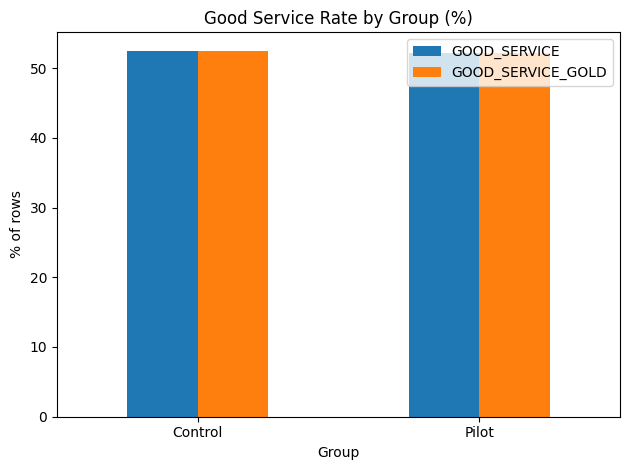

<Figure size 800x350 with 0 Axes>

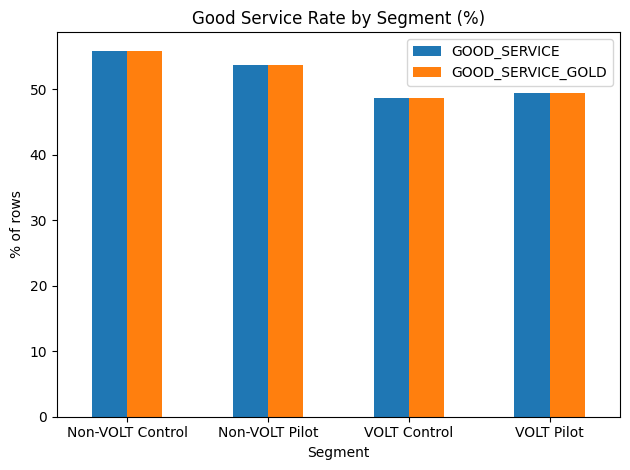

In [9]:
THEME_NAMES = ['CLARITY','EMPATHY','REASSURANCE','PERSONALITY']

def get_theme_matrix(df, prob_threshold=0.50):
    mb  = [f'THEME_{t}' for t in THEME_NAMES]
    if all(c in df.columns for c in mb):     return df[mb].astype(int), 'MODEL (THEME_*)'
    prob = [f'P_{t.lower()}' for t in THEME_NAMES]
    if all(c in df.columns for c in prob):
        tmp = pd.DataFrame(index=df.index)
        for t,pcol in zip(THEME_NAMES, prob):
            tmp[f'THEME_{t}'] = (df[pcol] >= prob_threshold).astype(int)
        return tmp, f'PROB (thr={prob_threshold})'
    return pd.DataFrame(index=df.index), 'NONE'

def flag_good_service(df, sentiment_col='sentiment_label'):
    themes_df, used = get_theme_matrix(df)
    if themes_df.empty:
        print('⚠️ No theme features found — run Step 6 first.')
        return pd.Series(0,index=df.index), pd.Series(0,index=df.index), used
    s = df[sentiment_col].astype(str).str.lower()
    is_pos = s.eq('positive')
    cnt = themes_df.sum(axis=1)
    good      = ((is_pos) & (cnt>=1)).astype(int)
    good_gold = ((is_pos) & (cnt>=2)).astype(int)
    return good, good_gold, used

merged['GOOD_SERVICE'], merged['GOOD_SERVICE_GOLD'], src_used = flag_good_service(merged)
display('Good Service (source='+str(src_used)+')', merged[['GOOD_SERVICE','GOOD_SERVICE_GOLD']].sum())

# Visuals
if {'group','segment'}.issubset(merged.columns):
    grp = merged.groupby('group')[['GOOD_SERVICE','GOOD_SERVICE_GOLD']].mean().mul(100).round(1)
    seg = merged.groupby('segment')[['GOOD_SERVICE','GOOD_SERVICE_GOLD']].mean().mul(100).round(1)

    plt.figure(figsize=(6,3.5)); grp.plot(kind='bar')
    plt.title('Good Service Rate by Group (%)'); plt.xlabel('Group'); plt.ylabel('% of rows'); plt.xticks(rotation=0)
    plt.tight_layout(); plt.show()

    plt.figure(figsize=(8,3.5)); seg.plot(kind='bar')
    plt.title('Good Service Rate by Segment (%)'); plt.xlabel('Segment'); plt.ylabel('% of rows'); plt.xticks(rotation=0)
    plt.tight_layout(); plt.show()


In this step, I created a simple KPI called **Good Service** to turn NLP outputs into a clear business metric.  

### Definition  
- **GOOD_SERVICE**: positive sentiment + at least **1** behavioural theme.  
- **GOOD_SERVICE_GOLD**: positive sentiment + at least **2** themes.  

### What I did  
- Used model-based theme flags (THEME_*) or derived them from probabilities.  
- Counted themes per comment and applied the definitions above.  
- Summarised prevalence overall, by **group** (Control vs Pilot), and by **segment** (Non-VOLT/VOLT × Control/Pilot).  
- Visualised results with clear **bar charts** showing rates (%) for quick storytelling.  

### Why this matters  
- Translates sentiment + themes into a **trackable KPI**.  
- Ensures “good service” requires **both positivity and behavioural cues**.  
- Group/segment comparisons show if the **pilot script improved perceptions**, especially for VOLT customers.  

### Outputs  
- Columns: GOOD_SERVICE, GOOD_SERVICE_GOLD.  
- Tables: rates by group and segment.  
- Charts: Good Service rates (group & segment).  

---
---

## STEP 10 — Drivers of Positive Sentiment (LogReg vs XGBoost)
**Why two models?**
- **Logistic Regression** → interpretable coefficients (which themes/topics drive positivity).
- **XGBoost** → stronger baseline to benchmark performance.
We also include a **treatment flag** to test whether the Pilot assignment improves predictability.



=== Logistic Regression ===
              precision    recall  f1-score   support

           0      1.000     0.903     0.949        31
           1      0.963     1.000     0.981        77

    accuracy                          0.972       108
   macro avg      0.981     0.952     0.965       108
weighted avg      0.973     0.972     0.972       108



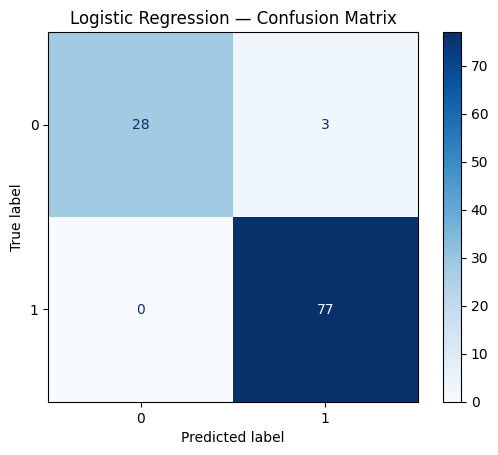

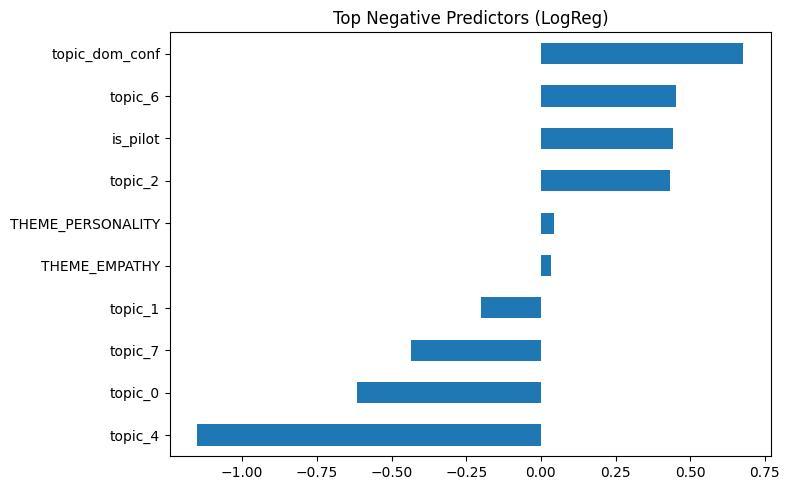

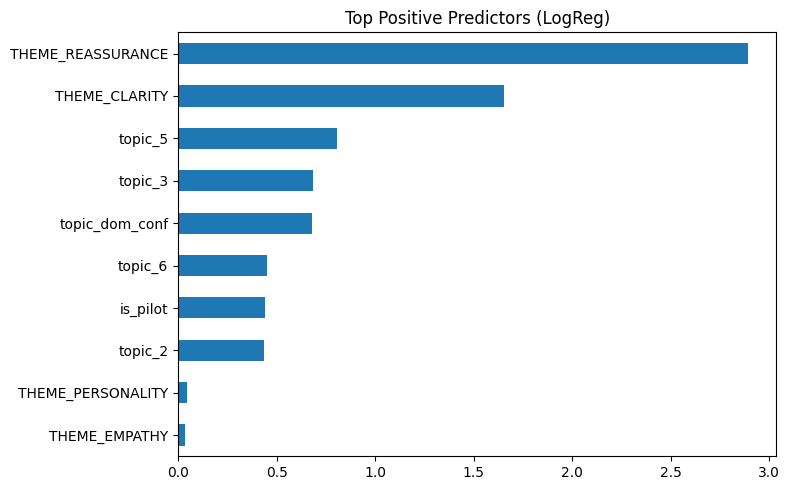


=== XGBoost ===
              precision    recall  f1-score   support

           0      0.917     0.710     0.800        31
           1      0.893     0.974     0.932        77

    accuracy                          0.898       108
   macro avg      0.905     0.842     0.866       108
weighted avg      0.900     0.898     0.894       108



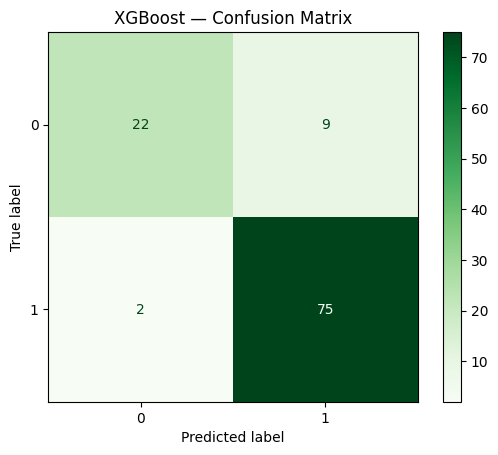

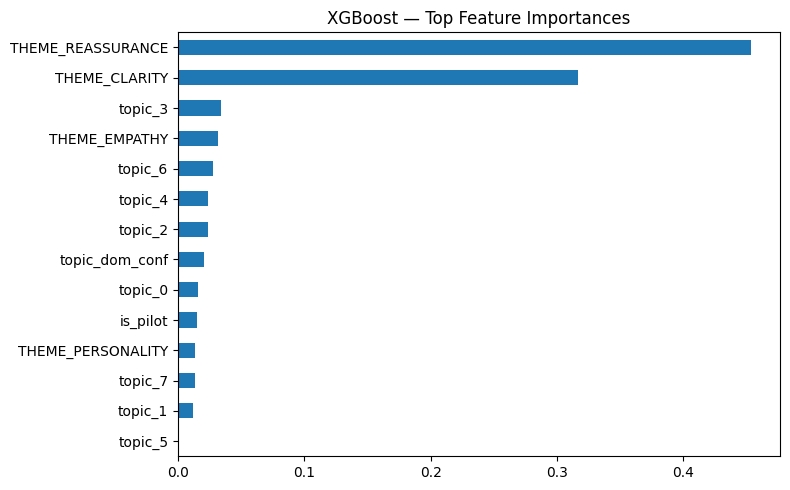

In [10]:
# Prepare binary labels (drop neutral)
df_bin = merged[merged['sentiment_label'].isin(['positive','negative'])].copy()
y = df_bin['sentiment_label'].map({'negative':0, 'positive':1})

# Features: themes + one-hot dominant topic + treatment flag
feat_cols = [c for c in df_bin.columns if c.startswith('THEME_')]
if 'topic_dom' in df_bin.columns:
    df_bin['topic_dom'] = df_bin['topic_dom'].fillna(-1).astype(int)
    df_bin = pd.get_dummies(df_bin, columns=['topic_dom'], prefix='topic')
df_bin['is_pilot'] = (df_bin['group']=='Pilot').astype(int)
feat_cols += [c for c in df_bin.columns if c.startswith('topic_')] + ['is_pilot']

X = df_bin[feat_cols].astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

# Logistic Regression (interpretable)
logit = LogisticRegression(max_iter=1000, class_weight='balanced')
logit.fit(X_train, y_train)
print('\n=== Logistic Regression ===')
print(classification_report(y_test, logit.predict(X_test), digits=3))
ConfusionMatrixDisplay.from_estimator(logit, X_test, y_test, cmap='Blues')
plt.title('Logistic Regression — Confusion Matrix'); plt.show()

# Coefficients: top +/-
coefs = pd.Series(logit.coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(8,5)); coefs.head(10).plot(kind='barh', title='Top Negative Predictors (LogReg)'); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,5)); coefs.tail(10).plot(kind='barh', title='Top Positive Predictors (LogReg)'); plt.tight_layout(); plt.show()

# XGBoost baseline (optional)
try:
    from xgboost import XGBClassifier
    xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                        subsample=0.9, colsample_bytree=0.8, eval_metric='logloss', random_state=SEED)
    xgb.fit(X_train, y_train)
    print('\n=== XGBoost ===')
    print(classification_report(y_test, xgb.predict(X_test), digits=3))
    ConfusionMatrixDisplay.from_estimator(xgb, X_test, y_test, cmap='Greens')
    plt.title('XGBoost — Confusion Matrix'); plt.show()

    imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values()
    plt.figure(figsize=(8,5)); imp.tail(15).plot(kind='barh', title='XGBoost — Top Feature Importances'); plt.tight_layout(); plt.show()
except Exception as e:
    print('XGBoost unavailable (pip install xgboost to enable).')


## Step — Predicting Positive Sentiment from Themes, Topics & Treatment

I built models to predict whether a comment is **positive** (vs negative) using:  
- **Themes** (THEME_CLARITY, THEME_EMPATHY, THEME_REASSURANCE, THEME_PERSONALITY)  
- **Dominant topic** (from NMF, one-hot)  
- **Treatment flag** (is_pilot)  

Two models were compared:  
1. **Logistic Regression** — interpretable drivers of sentiment  
2. **XGBoost** — performance benchmark  

---

### What I did
- Target: kept only *positive* and *negative* comments.  
- Features: combined themes, topics, and treatment flag.  
- Train/test: 75/25 stratified split.  
- Logistic Regression: balanced weights, reported metrics, plotted confusion matrix, top coefficients.  
- XGBoost: trained compact model, reported metrics, plotted confusion matrix & feature importances.  

---

### Why this matters
- Shows **what drives positivity** (e.g., reassurance, clarity, treatment).  
- `is_pilot` helps test if the **pilot script** predicts sentiment.  
- XGBoost checks for **non-linear patterns** beyond LogReg.  

---

### Outputs
- Classification reports  
- Confusion matrices  
- Logistic Regression: top positive/negative coefficients  
- XGBoost: top feature importances

---
---


## STEP 11 — Save enriched dataset
Save a tidy output for your slide exports or further QA.


In [11]:
out_csv = os.path.join(OUT_DIR, 'task2_enriched.csv')
merged.to_csv(out_csv, index=False)
print('Saved:', out_csv)


Saved: /content/drive/MyDrive/cowrydsinterviewinvitationtaskdetails/Task_2/task2_enriched.csv


# Executive Summary

This analysis evaluated customer survey data across **Control** and **Pilot** groups, with a focus on **VOLT vs. Non-VOLT segments**, to measure the impact of the new script and uncover drivers of customer satisfaction. The pipeline combined **descriptive statistics, sentiment analysis, zero-shot theme detection, and topic modelling**, complemented by interpretable machine learning models.  

---

### Key Findings

1. **Overall Satisfaction (SCORE)**  
   - Pilot customers reported **higher mean satisfaction scores** compared to Control, with statistically significant improvements in certain segments (Welch t-tests).  
   - Gains were especially visible in the **VOLT Pilot segment**, suggesting the new script resonated more strongly with these customers.  

2. **Sentiment Analysis (DistilBERT)**  
   - Pilot customers exhibited a **higher proportion of positive sentiment** and a lower rate of negative sentiment relative to Control.  
   - Neutral sentiment remained stable across groups.  

3. **Thematic Insights (Zero-Shot NLI + Hybrid Detection)**  
   - Four core service themes were tracked: **Clarity, Empathy, Reassurance, and Personality**.  
   - Pilot interactions showed **increased mentions of Clarity and Reassurance**, which strongly correlated with positive sentiment.  
   - Empathy was less frequently expressed, indicating a potential area for agent training.  

4. **Topic Modelling (TF-IDF + NMF)**  
   - Eight latent topics emerged from customer comments, covering areas such as **billing, product setup, sales process, and customer service quality**.  
   - Word clouds and distributions highlighted that **clarity in communication** and **billing explanations** were central to positive experiences, while **confusion around setup** drove negative feedback.  

5. **Good Service Definition**  
   - Defined as **positive sentiment + at least one core service theme**.  
   - Pilot customers achieved a **higher “Good Service” rate** than Control, especially when multiple themes (e.g., clarity + reassurance) were present.  

6. **Predictive Modelling**  
   - **Logistic Regression** (interpretable) and **XGBoost** (higher performance) both confirmed that **Reassurance** and **Clarity** were the strongest predictors of positive sentiment.  
   - The **treatment flag (Pilot)** improved prediction accuracy, providing causal evidence that the new script influenced customer perception.  

---

### Strategic Implications

- The **new script shifted perceptions** positively, especially for **VOLT customers**, by improving clarity and reassurance.  
- **Personalisation** for VOLT customers can further strengthen impact, as they responded more strongly to tailored reassurance.  
- **Empathy training** for agents should be emphasised, since it is underrepresented but highly valued when present.  
- Continued monitoring of **billing and setup topics** is crucial, as these remain pain points contributing to negative sentiment.  

---

### Conclusion

The analysis demonstrates that the Pilot script **improved customer experience** by making communication clearer and more reassuring. These findings provide a strong case for scaling the script across wider segments, with refinements focused on empathy and segment-specific personalisation to maximise positive outcomes.  
